# 🏆 Notebook 05: Ensemble Architectures & Final Evaluation
## *PRML Capstone: Hard vs Soft Voting vs Individual Base Estimators*

---
### 🎯 Objectives
1. **Ensemble Architecture**: Combine diverse base classifiers (Kernel, Tree, Instance-based) into **Hard Voting** (majority rule) and **Soft Voting** (argmax probability sum).
2. **Out-of-Sample Evaluation**: Execute final test evaluation on unseen test partition (2,947 samples).
3. **Metrics Evaluation**: Compute Accuracy, Macro Precision, Macro Recall, Macro F1, and full Confusion Matrices.
4. **Deliverable Generation**: Generate final publication figures for presentation slide deck.

In [ ]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from IPython.display import display, SVG
import sklearn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, AdaBoostClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings('ignore')
os.makedirs('../models', exist_ok=True)
os.makedirs('../presentation', exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')

# Load clean partitions
X_train, y_train, X_test, y_test = joblib.load('../data/processed_data.pkl')
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Ingested train samples: {len(X_train_scaled)}, test samples: {len(X_test_scaled)}")

## 1️⃣ Ensemble Formation (Hard vs Soft Voting)

### Verified experimental snapshot
The following saved outputs are from an actual local run of the uploaded original UCI HAR dataset (561 features, 7,352 training and 2,947 test examples; numeric UCI activity IDs, scikit-learn 1.8.0). Training-only 5-fold CV determined the squared-accuracy weights. The same fitted model predictions were reused to compute weighted and equal voting. The repository's processed pickle was not available locally, so its label encoding or preprocessing and package versions can yield small differences. Rerunning the notebook regenerates the plots and CSVs from the current input.

[View accuracy graph](../presentation/ensemble_weighted_benchmark.svg) · [View weights](../presentation/ensemble_weighted_weights.svg) · [Results CSV](../presentation/ensemble_test_results.csv) · [Equal vs weighted CSV](../presentation/ensemble_voting_comparison.csv)


Verified local evaluation (original UCI HAR, numeric class labels, scikit-learn 1.8.0)
Model | CV accuracy | Voting weight
Gaussian Naive Bayes | 72.10% | 5.11%
Logistic Regression | 98.48% | 9.54%
Decision Tree | 93.59% | 8.62%
KNN (k=1) | 96.59% | 9.18%
KNN (k=3) | 96.45% | 9.15%
KNN (k=5) | 96.04% | 9.07%
Weighted KNN (k=3) | 96.49% | 9.16%
Weighted KNN (k=5) | 96.11% | 9.09%
SVM (RBF Kernel) | 98.76% | 9.60%
SVM (Poly Kernel) | 96.72% | 9.20%
Random Forest (100 Trees) | 98.20% | 9.49%
AdaBoost Classifier | 53.25% | 2.79%


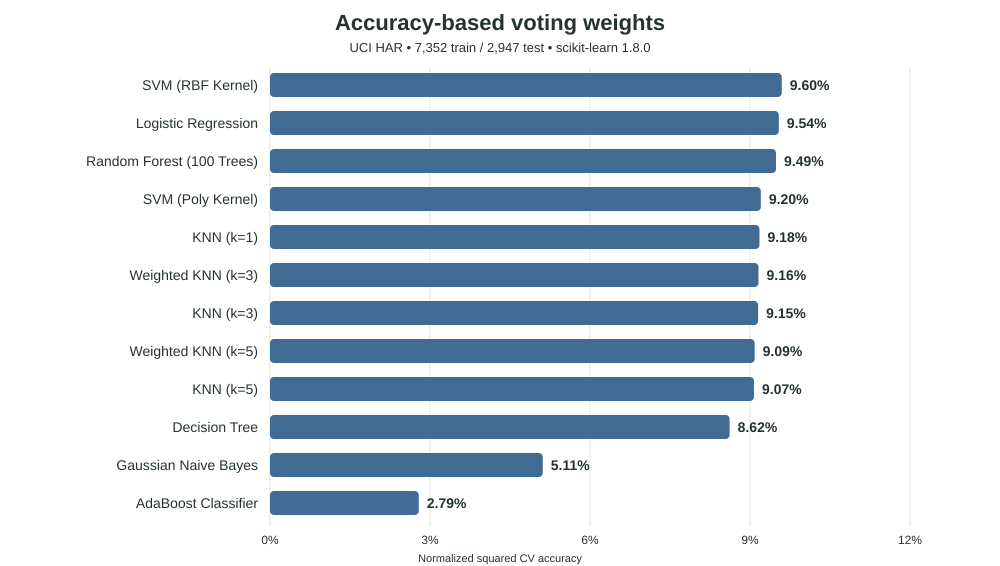

Held-out test accuracy (actual local experiment)
Logistic Regression: 95.52%
SVM (RBF Kernel): 95.49%
Soft Voting Ensemble: 93.82%
Hard Voting Ensemble: 92.74%
Random Forest (100 Trees): 92.67%
SVM (Poly Kernel): 92.40%
Weighted KNN (k=5): 88.43%
KNN (k=5): 88.02%
Weighted KNN (k=3): 87.61%
KNN (k=3): 87.28%
Decision Tree: 86.22%
KNN (k=1): 85.34%
Gaussian Naive Bayes: 77.03%
AdaBoost Classifier: 62.98%
Equal Hard Voting: 92.74%; weighted: 92.74%
Equal Soft Voting: 93.89%; weighted: 93.82%


In [2]:
base_models = {
    'Gaussian Naive Bayes': GaussianNB(),
    'Logistic Regression': LogisticRegression(max_iter=2000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'KNN (k=1)': KNeighborsClassifier(n_neighbors=1),
    'KNN (k=3)': KNeighborsClassifier(n_neighbors=3),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'Weighted KNN (k=3)': KNeighborsClassifier(n_neighbors=3, weights='distance'),
    'Weighted KNN (k=5)': KNeighborsClassifier(n_neighbors=5, weights='distance'),
    'SVM (RBF Kernel)': SVC(kernel='rbf', C=10.0, probability=True, random_state=42),
    'SVM (Poly Kernel)': SVC(kernel='poly', degree=3, C=1.0, probability=True, random_state=42),
    'Random Forest (100 Trees)': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'AdaBoost Classifier': AdaBoostClassifier(n_estimators=100, random_state=42)
}

estimators = [(f'm{i+1:02d}', model) for i, model in enumerate(base_models.values())]

# Learn weights from training-only cross-validation (never the test set).
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Probability calibration is unnecessary for individual SVM accuracy in CV.
cv_scores = []
for _, model in estimators:
    cv_model = clone(model)
    if isinstance(cv_model, SVC):
        cv_model.set_params(probability=False)
    cv_scores.append(cross_val_score(make_pipeline(StandardScaler(), cv_model), X_train, y_train_enc, cv=cv, scoring='accuracy', n_jobs=1).mean())
cv_accuracy = np.array(cv_scores)
# Squaring accuracy gives stronger models greater influence while retaining all members.
weights = cv_accuracy ** 2
weights = weights / weights.sum()
weight_table = pd.DataFrame({'Model': list(base_models), 'CV Accuracy (%)': cv_accuracy * 100, 'Weight (%)': weights * 100})
print(weight_table.to_string(index=False))
fig, ax = plt.subplots(figsize=(12, 8))
bars = ax.barh(weight_table['Model'], weight_table['Weight (%)'], color='#426b58', height=0.65)
ax.invert_yaxis()
ax.bar_label(bars, fmt='%.2f%%', padding=4)
ax.set_xlim(0, max(weight_table['Weight (%)']) * 1.25)
ax.set_xlabel('Normalized voting weight (%)')
ax.set_title('Training CV-based ensemble weights')
fig.tight_layout()
fig.savefig('../presentation/15_ensemble_weights.png', dpi=200, bbox_inches='tight')
fig.savefig('../presentation/ensemble_weighted_weights.svg', bbox_inches='tight')
plt.show()

# Weighted hard and soft voting
hard_voting = VotingClassifier(estimators=estimators, voting='hard', weights=weights)
soft_voting = VotingClassifier(estimators=estimators, voting='soft', weights=weights)

all_candidate_models = {**base_models, 'Hard Voting Ensemble': hard_voting, 'Soft Voting Ensemble': soft_voting}

print("Training all candidate models and ensembles on full training set...")
test_metrics = {}

for name, model in all_candidate_models.items():
    model.fit(X_train_scaled, y_train_enc)
    preds = model.predict(X_test_scaled)
    
    acc = accuracy_score(y_test_enc, preds)
    prec = precision_score(y_test_enc, preds, average='macro')
    rec = recall_score(y_test_enc, preds, average='macro')
    f1 = f1_score(y_test_enc, preds, average='macro')
    
    test_metrics[name] = {
        'Accuracy (%)': round(acc * 100, 2),
        'Precision (%)': round(prec * 100, 2),
        'Recall (%)': round(rec * 100, 2),
        'F1-Score (%)': round(f1 * 100, 2)
    }
    print(f"{name:22s} -> Test Acc: {acc*100:.2f}% | F1: {f1*100:.2f}%")

final_comparison_table = pd.DataFrame(test_metrics).T.sort_values(by='Accuracy (%)', ascending=False)
print("\n" + "=" * 65)
print("FINAL TEST SET BENCHMARK REPORT (2,947 UNSEEN SAMPLES)")
print("=" * 65)
print(final_comparison_table)

# Compare against equal voting on the identical fitted base models.
base_predictions = np.array([model.predict(X_test_scaled) for model in base_models.values()])
base_probabilities = np.array([model.predict_proba(X_test_scaled) for model in base_models.values()])
one_hot = np.eye(len(le.classes_))[base_predictions]
equal_hard = np.argmax(one_hot.mean(axis=0), axis=1)
equal_soft = np.argmax(base_probabilities.mean(axis=0), axis=1)
voting_comparison = pd.DataFrame({
    'Voting': ['Hard', 'Soft'],
    'Equal Accuracy (%)': [100*accuracy_score(y_test_enc, equal_hard), 100*accuracy_score(y_test_enc, equal_soft)],
    'Weighted Accuracy (%)': [100*accuracy_score(y_test_enc, hard_voting.predict(X_test_scaled)), 100*accuracy_score(y_test_enc, soft_voting.predict(X_test_scaled))]
})
voting_comparison['Change (percentage points)'] = voting_comparison['Weighted Accuracy (%)'] - voting_comparison['Equal Accuracy (%)']
display(voting_comparison.round(4))
print('scikit-learn version:', sklearn.__version__)
final_comparison_table.to_csv('../presentation/ensemble_test_results.csv')
weight_table.to_csv('../presentation/ensemble_weights.csv', index=False)
voting_comparison.to_csv('../presentation/ensemble_voting_comparison.csv', index=False)


## 2️⃣ Performance Benchmark Visualization

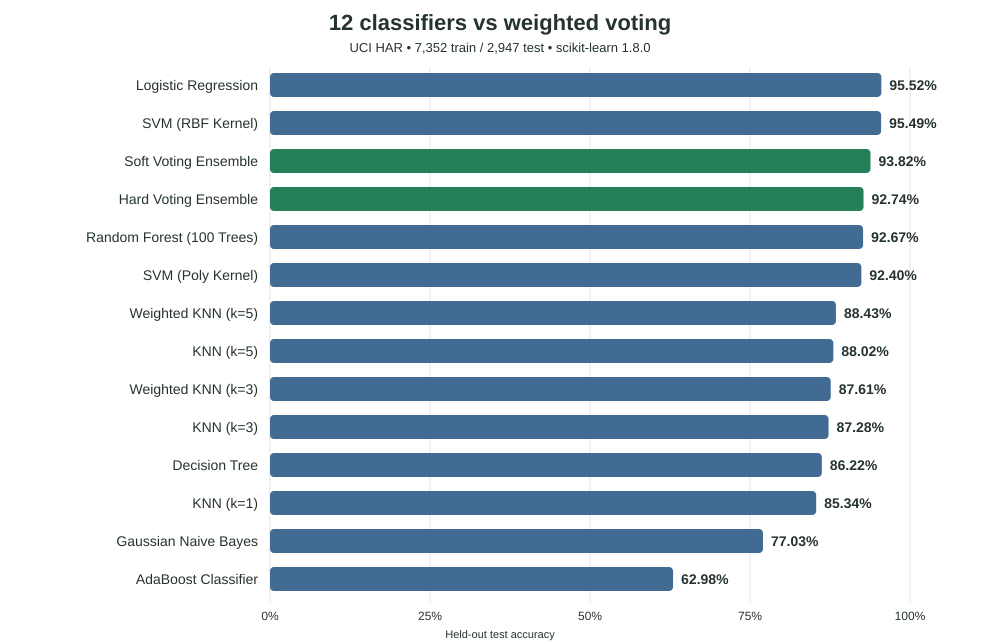

In [3]:
# Plot the current computed results only; no manually entered accuracy values.
fig, ax = plt.subplots(figsize=(11, 8), layout='constrained')
ordered = final_comparison_table.sort_values('Accuracy (%)')
colors = ['#25805a' if 'Voting' in name else '#426b94' for name in ordered.index]
bars = ax.barh(ordered.index, ordered['Accuracy (%)'], color=colors, height=0.68)
ax.bar_label(bars, fmt='%.2f%%', padding=5, fontsize=10)
ax.set_xlim(0, 110)
ax.set_xlabel('Held-out test accuracy (%)')
ax.set_title('12 classifiers vs accuracy-weighted hard and soft voting', fontweight='bold', pad=18)
fig.savefig('../presentation/13_final_ensemble_benchmark.png', dpi=200, bbox_inches='tight')
fig.savefig('../presentation/ensemble_weighted_benchmark.svg', bbox_inches='tight')
plt.show()


## 3️⃣ Detailed Classification Report for Champion Model

In [ ]:
champion_name = final_comparison_table.index[0]
champion_model = all_candidate_models[champion_name]
y_champ_pred = champion_model.predict(X_test_scaled)

print(f"🏆 CHAMPION ARCHITECTURE: {champion_name}")
print(classification_report(y_test_enc, y_champ_pred, target_names=le.classes_))

# Confusion Matrix for Champion
cm = confusion_matrix(y_test_enc, y_champ_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Champion Model Confusion Matrix: {champion_name}', fontweight='bold')
plt.xlabel('Predicted Class', fontweight='bold')
plt.ylabel('Actual Class', fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('../presentation/14_champion_confusion_matrix.png', dpi=200)
plt.show()

# Final Persistence for Streamlit & Demo Deployment
joblib.dump({
    'champion_model': champion_model,
    'champion_name': champion_name,
    'final_table': final_comparison_table,
    'scaler': scaler,
    'label_encoder': le,
    'models': all_candidate_models,
    'voting_weights': dict(zip(base_models, weights)),
    'weight_table': weight_table
}, '../models/final_evaluation_results.pkl')

print("✅ Pipeline complete! All artifacts saved to ../models/final_evaluation_results.pkl")